In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt

In [16]:
#constants
IMAGE_SIZE=128
BATCH_SIZE=32
CHANNELS=3
EPOCHS=10

In [4]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "PCOS_dataset",
    shuffle=True,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 11784 files belonging to 2 classes.


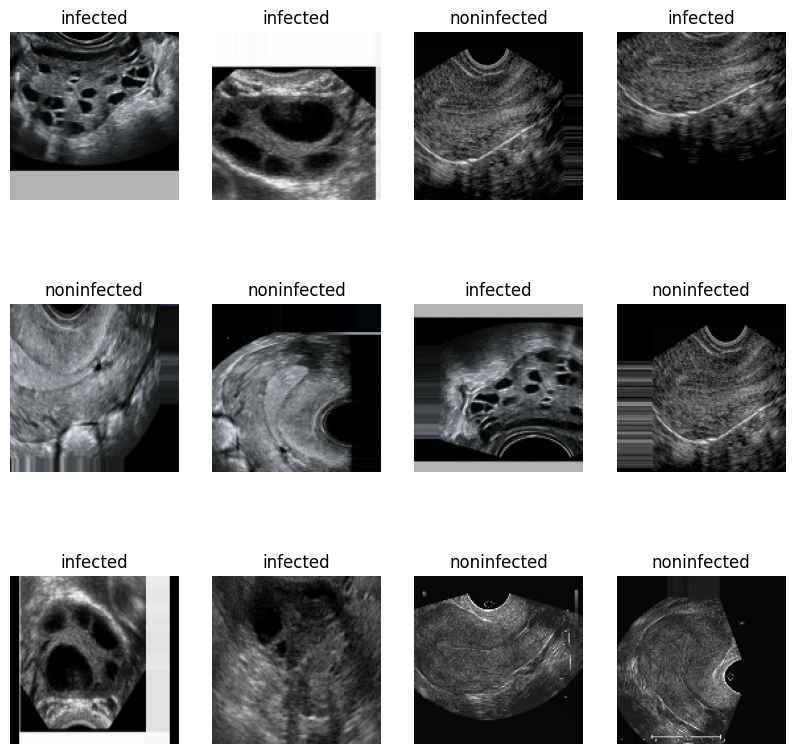

In [5]:
class_names=dataset.class_names
plt.figure(figsize=(10,10))
for image_batch, label_batch in dataset.take(1):
    for i in range(12):
        ax=plt.subplot(3,4,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.axis("off")
        plt.title(class_names[label_batch[i]])

In [6]:
len(dataset)

369

In [7]:
def get_dataset_partitions(ds,train_split=0.8,val_split=0.1,test_split=0.1,shuffle=True, shuffle_size=1000):
    ds_size=len(ds)
    if shuffle:
        ds=ds.shuffle(shuffle_size, seed=12)
    train_size=int(train_split*ds_size)
    val_size=int(val_split*ds_size)

    train_Ds=ds.take(train_size)
    val_Ds=ds.skip(train_size).take(val_size)
    test_Ds=ds.skip(train_size).skip(val_size)
    return train_Ds, val_Ds, test_Ds

In [8]:
train_ds,val_ds, test_ds=get_dataset_partitions(dataset)

In [9]:
train_ds=train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds=val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds=test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

In [10]:
resizing_and_rescaling = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE,IMAGE_SIZE),
    layers.Rescaling(1.0/255)
])

In [11]:
data_augmentation=tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2)
])

In [12]:
print(len(train_ds),
len(test_ds),
len(val_ds))

295 38 36


In [17]:
input_shape=(BATCH_SIZE,IMAGE_SIZE,IMAGE_SIZE, CHANNELS)
classes=2
model = models.Sequential([
    resizing_and_rescaling,
    data_augmentation,
    layers.Conv2D(32,(3,3),activation='relu',input_shape=input_shape),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(32,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(32,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(32,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(classes, activation='softmax'),
])

model.build(input_shape=input_shape)

In [18]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (32, 128, 128, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_1 (Sequential)            │ (32, 128, 128, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (32, 126, 126, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (32, 63, 63, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (32, 61, 61, 32)            │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (32, 30, 30, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (32, 28, 28, 32)            │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (32, 14, 14, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (32, 12, 12, 32)            │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (32, 6, 6, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (32, 1152)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (32, 64)                    │          73,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (32, 2)                     │             130 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 102,562 (400.63 KB)

 Trainable params: 102,562 (400.63 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [20]:
history = model.fit(
    train_ds,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    validation_data=val_ds
)

Epoch 1/10


C:\Users\acerr\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


295/295 ━━━━━━━━━━━━━━━━━━━━ 193s 429ms/step - accuracy: 0.8892 - loss: 0.2554 - val_accuracy: 0.9410 - val_loss: 0.1461
Epoch 2/10
295/295 ━━━━━━━━━━━━━━━━━━━━ 110s 371ms/step - accuracy: 0.9188 - loss: 0.1957 - val_accuracy: 0.9479 - val_loss: 0.1508
Epoch 3/10
295/295 ━━━━━━━━━━━━━━━━━━━━ 108s 367ms/step - accuracy: 0.9309 - loss: 0.1666 - val_accuracy: 0.9566 - val_loss: 0.1200
Epoch 4/10
295/295 ━━━━━━━━━━━━━━━━━━━━ 144s 376ms/step - accuracy: 0.9391 - loss: 0.1484 - val_accuracy: 0.9575 - val_loss: 0.1097
Epoch 5/10
295/295 ━━━━━━━━━━━━━━━━━━━━ 313s 355ms/step - accuracy: 0.9427 - loss: 0.1369 - val_accuracy: 0.8898 - val_loss: 0.4166
Epoch 6/10
295/295 ━━━━━━━━━━━━━━━━━━━━ 146s 369ms/step - accuracy: 0.9530 - loss: 0.1209 - val_accuracy: 0.9097 - val_loss: 0.3724
Epoch 7/10
295/295 ━━━━━━━━━━━━━━━━━━━━ 109s 370ms/step - accuracy: 0.9533 - loss: 0.1196 - val_accuracy: 0.9670 - val_loss: 0.0950
Epoch 8/10
295/295 ━━━━━━━━━━━━━━━━━━━━ 111s 378ms/step - accuracy: 0.9594 - loss: 0.10

In [35]:
scores = model.evaluate(test_ds)

AttributeError: 'TFSMLayer' object has no attribute 'evaluate'

In [22]:
scores

[0.08124469965696335, 0.9530201554298401]

In [23]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

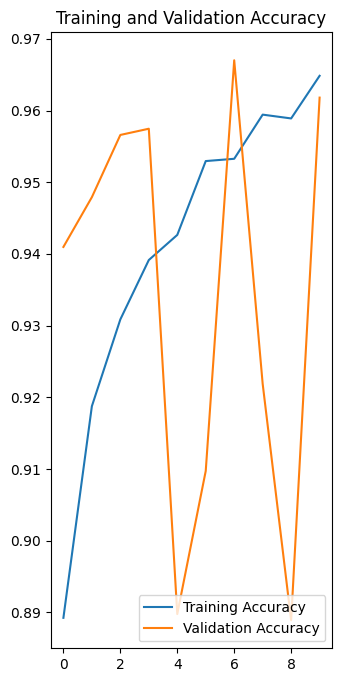

In [25]:
plt.figure(figsize=(8,8))
plt.subplot(1,2,1)
plt.plot(range(EPOCHS), acc , label="Training Accuracy")
plt.plot(range(EPOCHS) , val_acc, label="Validation Accuracy")
plt.legend(loc='lower right')
plt.title("Training and Validation Accuracy")
plt.savefig("Training and Validation Accuracy.png")
plt.show()

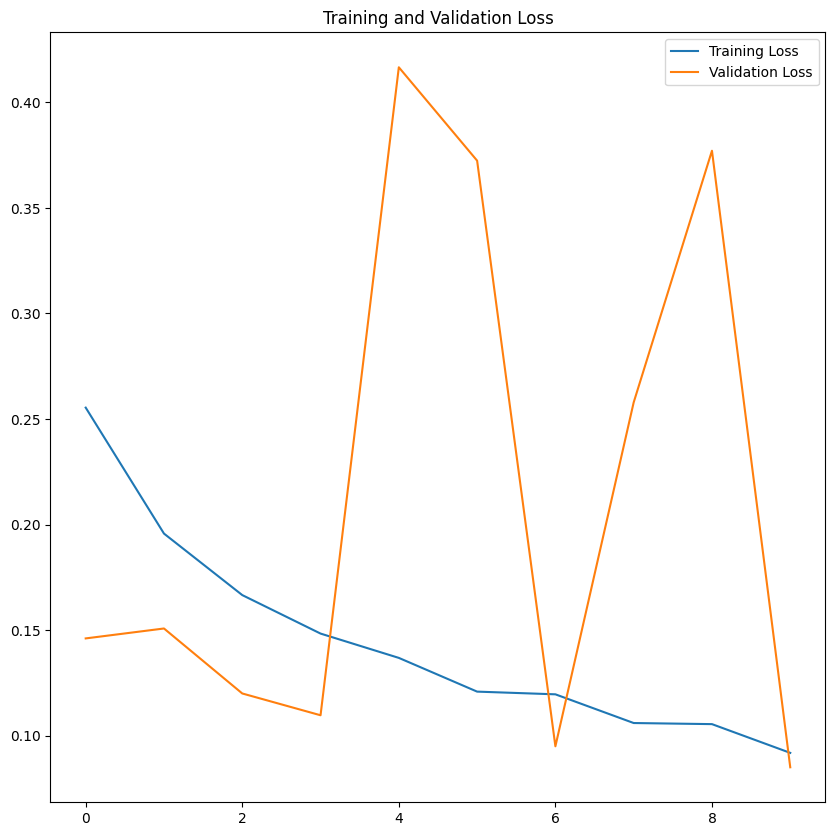

In [26]:
plt.figure(figsize=(10,10))
plt.plot(range(EPOCHS), loss, label="Training Loss")
plt.plot(range(EPOCHS), val_loss, label="Validation Loss")
plt.legend(loc="upper right")
plt.title("Training and Validation Loss")
plt.savefig("Training and Validation Loss.png")
plt.show()

In [28]:
model_version = 1 
model.export(f"../models/{model_version}")

INFO:tensorflow:Assets written to: ../models/1\assets


INFO:tensorflow:Assets written to: ../models/1\assets


Saved artifact at '../models/1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_20')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  2023206429088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2023206424512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2023320985600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2023320986640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2023205778512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2023320986848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2023320985808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2023320987264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2023320986016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2023320987680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2023320986224: TensorSpec(shape=(), 

In [29]:
history2 = model.fit(
    train_ds,
    validation_data = val_ds,
    initial_epoch = 10,
    epochs = 30,
    verbose = 1
)

Epoch 11/30


C:\Users\acerr\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


295/295 ━━━━━━━━━━━━━━━━━━━━ 107s 363ms/step - accuracy: 0.9647 - loss: 0.0927 - val_accuracy: 0.9297 - val_loss: 0.2071
Epoch 12/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 144s 369ms/step - accuracy: 0.9596 - loss: 0.1053 - val_accuracy: 0.9392 - val_loss: 0.1633
Epoch 13/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 106s 360ms/step - accuracy: 0.9708 - loss: 0.0795 - val_accuracy: 0.9392 - val_loss: 0.1875
Epoch 14/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 135s 337ms/step - accuracy: 0.9701 - loss: 0.0768 - val_accuracy: 0.9054 - val_loss: 0.2379
Epoch 15/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 148s 356ms/step - accuracy: 0.9696 - loss: 0.0802 - val_accuracy: 0.9306 - val_loss: 0.2139
Epoch 16/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 105s 356ms/step - accuracy: 0.9729 - loss: 0.0705 - val_accuracy: 0.8689 - val_loss: 0.6544
Epoch 17/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 145s 366ms/step - accuracy: 0.9774 - loss: 0.0646 - val_accuracy: 0.9340 - val_loss: 0.2368
Epoch 18/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 140s 360ms/step - accuracy: 0.9753 - los

In [30]:
import numpy as np

best_epoch = np.argmin(history.history['val_loss']) + 1
best_val_loss = min(history.history['val_loss'])
best_val_acc = history.history['val_accuracy'][best_epoch - 1]

print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)
print("Validation accuracy at best epoch:", best_val_acc)

Best epoch: 10
Best validation loss: 0.08503934741020203
Validation accuracy at best epoch: 0.9618055820465088


In [32]:
import tensorflow as tf

model = tf.keras.layers.TFSMLayer(
    "../models/1",
    call_endpoint="serve"
)

In [34]:
for images, labels in test_ds.take(1):
    predictions = model(images)
    print("Output:", predictions)
    print("Output shape:", predictions.shape)

Output: tf.Tensor(
[[3.29546026e-07 9.99999642e-01]
 [1.10825775e-02 9.88917470e-01]
 [2.13973857e-02 9.78602588e-01]
 [9.00392950e-01 9.96071100e-02]
 [9.99999642e-01 4.09062949e-07]
 [1.00000000e+00 6.50129429e-12]
 [9.99999881e-01 1.06679543e-07]
 [9.95825648e-01 4.17437125e-03]
 [1.00000000e+00 1.22137425e-10]
 [9.02516488e-03 9.90974844e-01]
 [1.00000000e+00 1.33885720e-08]
 [9.99817669e-01 1.82374104e-04]
 [1.67524785e-01 8.32475245e-01]
 [9.99999881e-01 1.69670898e-07]
 [9.99999166e-01 8.05832315e-07]
 [9.61885333e-01 3.81146409e-02]
 [1.22409286e-02 9.87759054e-01]
 [1.00000000e+00 6.57920329e-10]
 [1.30994071e-04 9.99868989e-01]
 [1.19680721e-04 9.99880314e-01]
 [9.98664498e-01 1.33546186e-03]
 [1.59502425e-03 9.98405039e-01]
 [2.30265432e-03 9.97697294e-01]
 [1.55597748e-02 9.84440207e-01]
 [1.08028855e-02 9.89197075e-01]
 [1.00000000e+00 2.16886058e-12]
 [1.03182286e-01 8.96817744e-01]
 [1.00000000e+00 8.53273124e-15]
 [9.96792018e-01 3.20796319e-03]
 [1.00000000e+00 1.74164

In [36]:
import numpy as np
from sklearn.metrics import accuracy_score

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model(images)

    # Handle dictionary output if necessary
    if isinstance(predictions, dict):
        predictions = next(iter(predictions.values()))

    y_pred.extend(np.argmax(predictions.numpy(), axis=1))

    if len(labels.shape) > 1:
        y_true.extend(np.argmax(labels.numpy(), axis=1))
    else:
        y_true.extend(labels.numpy())

accuracy = accuracy_score(y_true, y_pred)

print("Test Accuracy:", accuracy * 100, "%")

Test Accuracy: 96.81208053691275 %


In [37]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.99      0.97       702
           1       0.98      0.94      0.96       490

    accuracy                           0.97      1192
   macro avg       0.97      0.96      0.97      1192
weighted avg       0.97      0.97      0.97      1192



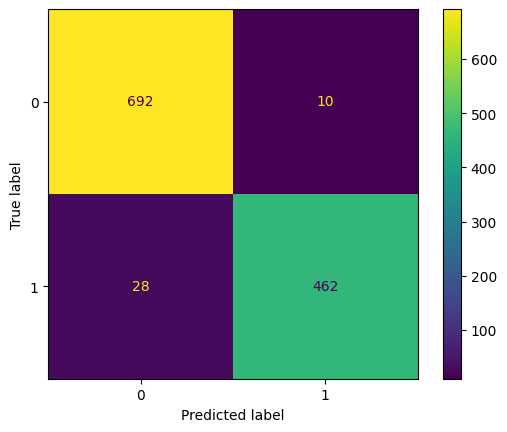

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [39]:
model = tf.keras.layers.TFSMLayer(
    "../models/1",
    call_endpoint="serve"
)

In [42]:
def predict(model, img):
    # Convert image to a tensor
    img = tf.convert_to_tensor(img, dtype=tf.float32)

    # Convert grayscale to RGB if it has 1 channel
    if img.shape[-1] == 1:
        img = tf.image.grayscale_to_rgb(img)

    # Add batch dimension if needed
    if len(img.shape) == 3:
        img = tf.expand_dims(img, axis=0)

    predictions = model(img)

    if isinstance(predictions, dict):
        predictions = next(iter(predictions.values()))

    predictions = predictions.numpy()

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * np.max(predictions[0]), 2)

    return predicted_class, confidence

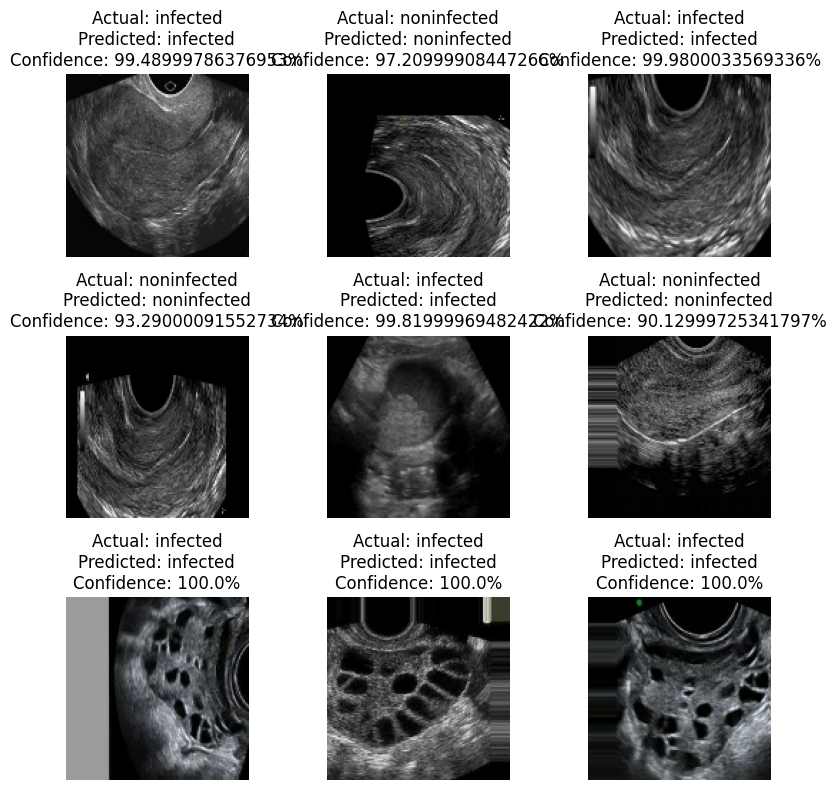

In [43]:
plt.figure(figsize=(8, 8))

for images, labels in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        img = images[i].numpy()

        predicted_class, confidence = predict(model, img)
        actual_class = class_names[int(labels[i])]

        plt.title(
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence}%"
        )

        # Display grayscale images correctly
        if img.shape[-1] == 1:
            plt.imshow(img.squeeze(), cmap="gray")
        else:
            plt.imshow(img.astype("uint8"))

        plt.axis("off")

plt.tight_layout()
plt.show()

In [50]:
image_path = "test004.jpg"

img = tf.keras.utils.load_img(
    image_path,
    target_size=(128, 128),
    color_mode="rgb"
)

img_array = tf.keras.utils.img_to_array(img)

predicted_class, confidence = predict(model, img_array)

print("Predicted class:", predicted_class)
print("Confidence:", confidence, "%")

Predicted class: noninfected
Confidence: 99.98 %


In [45]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\acerr\OneDrive\Desktop\Project PCOS\trainingPCOS
['.ipynb_checkpoints', 'Pcod_training.ipynb', 'PCOS_dataset', 'test001.jpg', 'Training and Validation Accuracy.png', 'Training and Validation Loss.png']
